# Figures 4, 5 and 6: simulated vs. theoretical growth rate, wavelength and lifetime

- **Part 6 (Figure 4)**: peak $\hat\sigma$ against $Ro$, $\hat h$, $\hat W$ and $\hat X_j$, with theory curves
- **Part 7 (Figure 5)**: dominant wavelength $\hat\lambda$ against the same parameters, with theory curves
- **Part 14**: data-completeness check, used as a **filter**. Tests whose growth-rate peak or lifetime hit the end of the record are listed in `INCOMPLETE_TESTS`
- **Part 16 (Figure 6)**: pooled comparison (growth rate, wavelength, lifetime) with least-squares fits and cluster-bootstrap 95% CIs, **excluding** the Part 14 tests

Simulation results are read from the NetCDF file written by `04_compute_growth_rate_wavelength_lifetime.ipynb`.

**Theory.** The linear stability problem (Eq. 3) is solved with the strip method of Ohshima (1987)
(see `02_ohshima_solver.ipynb`), in a faster but mathematically identical form: it is written in terms of
$\phi$ at the strip nodes, so continuity is built in and the problem becomes a small real eigenproblem.
Strip width $dx=0.05\,L_{jet}$ (converged to about 0.1%); the peak over $k$ is found by a coarse scan
followed by local refinement to $\Delta k \approx 10^{-4}$. Theory results are cached to
`figures/part6_theory_highres.npz` and `figures/part16_theory_per_test.npz` (computed in parallel if `joblib` is installed).

---
## Setup: imports, figure style, model profiles

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from scipy.linalg import eigvals, solve
from scipy.optimize import minimize_scalar

# AGU figure text: 8 pt
plt.rcParams.update({
    'font.family': 'sans-serif',
    'font.sans-serif': ['Arial', 'Helvetica', 'DejaVu Sans'],
    'font.size': 8,
    'axes.titlesize': 8,
    'axes.labelsize': 8,
    'xtick.labelsize': 8,
    'ytick.labelsize': 8,
    'legend.fontsize': 7,
    'legend.title_fontsize': 8,
})

MM_PER_IN = 25.4
AGU_2COL_WIDTH_IN = 170 / MM_PER_IN
AGU_MAX_HEIGHT_IN = 228 / MM_PER_IN

FIGURE_DIR = 'figures'
os.makedirs(FIGURE_DIR, exist_ok=True)

def add_panel_label(ax, label, x=0.03, y=0.96):
    """Small bold (a)/(b)/(c)/(d) panel tag, top-left corner (AGU multi-panel convention)."""
    ax.text(x, y, f'({label})', transform=ax.transAxes, fontsize=9,
            fontweight='bold', va='top', ha='left')

def save_agu_figure(fig, name):
    """Save as PDF (vector, for submission) and PNG (preview), both at 600 dpi.
    Exports RGB; AGU's final CMYK conversion is a separate step."""
    pdf_path = os.path.join(FIGURE_DIR, f'{name}.pdf')
    png_path = os.path.join(FIGURE_DIR, f'{name}.png')
    fig.savefig(pdf_path, dpi=600, bbox_inches='tight')
    fig.savefig(png_path, dpi=600, bbox_inches='tight')
    print(f"Saved {pdf_path} and {png_path}")

ARCTANH95 = np.arctanh(0.95)
F_CORIOLIS = 1e-5

def v_jet_shape(x, Xj_nd, Ljet_nd=1.0):
    x = np.asarray(x, dtype=float)
    return 0.5 * np.tanh((x - Xj_nd) / Ljet_nd)

def h_tanh(x, hs_nd, Xs_nd, Ws_nd=1.0):
    x = np.asarray(x, dtype=float)
    arg = 2 * ARCTANH95 * (x - Xs_nd) / Ws_nd
    return hs_nd + 0.5 * (1.0 - hs_nd) * (np.tanh(arg) + 1.0)

def domain_bounds(Xj_nd, Ljet_nd, Xs_nd, jet_mult=4.0, Ws_nd=1.0):
    x_min = min(Xs_nd - 0.5 * Ws_nd, Xj_nd - jet_mult * Ljet_nd)
    x_max = max(Xs_nd + 0.5 * Ws_nd, Xj_nd + jet_mult * Ljet_nd)
    return x_min, x_max

---
## Part 0 — Load the processed MOM6 results

Each file in `DATA_FILES` is opened in turn. If an experiment appears in more than one file, the
**first** file wins and the duplicate is reported. `test_source_file[test]` records which file each
experiment came from.

In [2]:
peak_results = {}
all_growth_rates, all_dominant_wavelengths = {}, {}
all_initial_time_idx      = {}   # time_idx of the reference time t0 (idx0)
all_lifetime_end_time_idx = {}   # end of the eddy lifetime
all_growth_peak_hit_wall  = {}
all_lifetime_hit_wall     = {}
test_source_file          = {}

try:
    import xarray as xr
    from pathlib import Path

    SAVE_DIR = Path('/g/data/nm03/ae7501/mom6_outputs/processed_results')
    DATA_FILES = [
        SAVE_DIR / '300_nondimplot_data_19_10.nc'
    ]

    def _scalar_int(da):
        """Per-experiment integer index, or NaN if missing."""
        v = float(da.values)
        return int(v) if np.isfinite(v) else np.nan

    def _scalar_bool(da):
        v = da.values
        try:
            return bool(v) if np.isfinite(float(v)) else False
        except (TypeError, ValueError):
            return bool(v)

    for path in DATA_FILES:
        try:
            with xr.open_dataset(path) as ds_file:
                ds = ds_file.load()
        except Exception as e:
            print(f"Could not open {path.name} ({type(e).__name__}: {e}) -- skipping this file")
            continue

        n_loaded, duplicates = 0, []
        for t in ds.experiment.values:
            t_str = str(t)
            if t_str in all_growth_rates:
                duplicates.append(t_str)
                continue
            all_growth_rates[t_str]         = ds['growth_rate'].sel(experiment=t).dropna('time_idx')
            all_dominant_wavelengths[t_str] = ds['dominant_wavelength'].sel(experiment=t).dropna('time_idx')
            if 'initial_time_idx' in ds:
                all_initial_time_idx[t_str] = _scalar_int(ds['initial_time_idx'].sel(experiment=t))
            if 'lifetime_end_time_idx' in ds:
                all_lifetime_end_time_idx[t_str] = _scalar_int(ds['lifetime_end_time_idx'].sel(experiment=t))
            if 'growth_peak_hit_wall' in ds:
                all_growth_peak_hit_wall[t_str] = _scalar_bool(ds['growth_peak_hit_wall'].sel(experiment=t))
            if 'lifetime_hit_wall' in ds:
                all_lifetime_hit_wall[t_str] = _scalar_bool(ds['lifetime_hit_wall'].sel(experiment=t))
            test_source_file[t_str] = path.name
            n_loaded += 1
        ds.close()

        msg = f"{path.name}: loaded {n_loaded} experiments"
        if duplicates:
            msg += (f"; skipped {len(duplicates)} already loaded from an earlier file "
                    f"({duplicates[0]} ... {duplicates[-1]})")
        print(msg)

    def peak_search_start(test):
        """First time_idx of the growth-rate peak search: the test's idx0 (0 if unknown)."""
        i0 = all_initial_time_idx.get(test, 0)
        return int(i0) if (i0 is not None and np.isfinite(i0)) else 0

    def analyze_peak_wavelength(test, t_start=None, t_end=4000, tol_frac=0.1, max_gap=3):
        # Search for the growth-rate peak from the test's own reference time idx0
        if t_start is None:
            t_start = peak_search_start(test)
        gr_da, dwl_da = xr.align(all_growth_rates[test], all_dominant_wavelengths[test], join='inner')
        window = gr_da.sel(time_idx=slice(t_start, t_end))
        if window.size == 0 or window.isnull().all():
            return np.nan, np.nan
        peak_pos  = int(window.fillna(-np.inf).argmax(dim='time_idx'))
        peak_tidx = int(window.time_idx.values[peak_pos])
        peak_growth = float(window.values[peak_pos])
        if peak_tidx not in dwl_da.time_idx.values:
            return peak_growth, np.nan
        peak_wavelength = float(dwl_da.sel(time_idx=peak_tidx))
        return peak_growth, peak_wavelength

    for test in all_growth_rates:
        pg, pw = analyze_peak_wavelength(test)

        # Eddy lifetime: idx0 to the last timestep at which the peak-growth wavelength is still dominant
        idx0             = all_initial_time_idx.get(test, np.nan)
        idx_lifetime_end = all_lifetime_end_time_idx.get(test, np.nan)
        lifetime_steps = (idx_lifetime_end - idx0) if (np.isfinite(idx0) and np.isfinite(idx_lifetime_end)) else np.nan

        peak_results[test] = {'peak_growth': pg, 'peak_wavelength': pw, 'lifetime_steps': lifetime_steps}

    print(f"Loaded peak_results for {len(peak_results)} experiments in total")
except Exception as e:
    print(f"Could not load NetCDF data in this environment ({type(e).__name__}: {e})")
    print("peak_results is empty -- all panels below will fall back to theory-only.")

300_nondimplot_data_19_10.nc: loaded 113 experiments
Loaded peak_results for 113 experiments in total


---
## Experiment design

`experiment_params` gives `(slope_width_km, slope_height_m, jet_width_m, u_m_s, abyss_depth_m)`
for every test; `sets` groups them; `set11_offsets` gives the jet-centre positions used in panel (d).

In [3]:
experiment_params = {
    # set1 -- width sweep, jet_width=5000, u=0.2
    "test160": (5,  400, 5000, 0.2, 500), "test161": (15, 400, 5000, 0.2, 500),
    "test162": (25, 400, 5000, 0.2, 500), "test163": (35, 400, 5000, 0.2, 500),
    "test164": (45, 400, 5000, 0.2, 500), "test165": (55, 400, 5000, 0.2, 500),
    "test166": (65, 400, 5000, 0.2, 500), "test167": (75, 400, 5000, 0.2, 500),
    "test168": (85, 400, 5000, 0.2, 500), "test169": (95, 400, 5000, 0.2, 500),
    # set2 -- width sweep, jet_width=10000, u=0.2
    "test170": (5,  400, 10000, 0.2, 500), "test171": (15, 400, 10000, 0.2, 500),
    "test172": (25, 400, 10000, 0.2, 500), "test173": (35, 400, 10000, 0.2, 500),
    "test174": (45, 400, 10000, 0.2, 500), "test175": (55, 400, 10000, 0.2, 500),
    "test176": (65, 400, 10000, 0.2, 500), "test177": (75, 400, 10000, 0.2, 500),
    "test178": (85, 400, 10000, 0.2, 500), "test179": (95, 400, 10000, 0.2, 500),
    # set3 -- width sweep, jet_width=15000, u=0.2
    "test180": (5,  400, 15000, 0.2, 500), "test181": (15, 400, 15000, 0.2, 500),
    "test182": (25, 400, 15000, 0.2, 500), "test183": (35, 400, 15000, 0.2, 500),
    "test184": (45, 400, 15000, 0.2, 500), "test185": (55, 400, 15000, 0.2, 500),
    "test186": (65, 400, 15000, 0.2, 500), "test187": (75, 400, 15000, 0.2, 500),
    "test188": (85, 400, 15000, 0.2, 500), "test189": (95, 400, 15000, 0.2, 500),
    # set4 -- height sweep, jet_width=5000, u=0.2
    "test190": (50,  25, 5000, 0.2, 125), "test191": (50,  50, 5000, 0.2, 150),
    "test192": (50, 100, 5000, 0.2, 200), "test193": (50, 150, 5000, 0.2, 250),
    "test194": (50, 200, 5000, 0.2, 300), "test195": (50, 250, 5000, 0.2, 350),
    "test196": (50, 300, 5000, 0.2, 400), "test197": (50, 350, 5000, 0.2, 450),
    "test198": (50, 375, 5000, 0.2, 475),
    # set5 -- height sweep, jet_width=10000, u=0.2
    "test199": (50,  25, 10000, 0.2, 125), "test200": (50,  50, 10000, 0.2, 150),
    "test201": (50, 100, 10000, 0.2, 200), "test202": (50, 150, 10000, 0.2, 250),
    "test203": (50, 200, 10000, 0.2, 300), "test204": (50, 250, 10000, 0.2, 350),
    "test205": (50, 300, 10000, 0.2, 400), "test206": (50, 350, 10000, 0.2, 450),
    "test207": (50, 375, 10000, 0.2, 475),
    # set6 -- width sweep, jet_width=5000, u=0.3
    "test208": (5,  400, 5000, 0.3, 500), "test209": (15, 400, 5000, 0.3, 500),
    "test210": (25, 400, 5000, 0.3, 500), "test211": (35, 400, 5000, 0.3, 500),
    "test212": (45, 400, 5000, 0.3, 500), "test213": (55, 400, 5000, 0.3, 500),
    "test214": (65, 400, 5000, 0.3, 500), "test215": (75, 400, 5000, 0.3, 500),
    "test216": (85, 400, 5000, 0.3, 500), "test217": (95, 400, 5000, 0.3, 500),
    # set7 -- width sweep, jet_width=10000, u=0.3
    "test218": (5,  400, 10000, 0.3, 500), "test219": (15, 400, 10000, 0.3, 500),
    "test220": (25, 400, 10000, 0.3, 500), "test221": (35, 400, 10000, 0.3, 500),
    "test222": (45, 400, 10000, 0.3, 500), "test223": (55, 400, 10000, 0.3, 500),
    "test224": (65, 400, 10000, 0.3, 500), "test225": (75, 400, 10000, 0.3, 500),
    "test226": (85, 400, 10000, 0.3, 500), "test227": (95, 400, 10000, 0.3, 500),
    # set8 -- jet-center-offset sweep, jet_width=5000, u=0.2, width=55km, height=400m fixed
    "test228": (55, 400, 5000, 0.2, 500), "test229": (55, 400, 5000, 0.2, 500),
    "test230": (55, 400, 5000, 0.2, 500), "test231": (55, 400, 5000, 0.2, 500),
    "test232": (55, 400, 5000, 0.2, 500), "test233": (55, 400, 5000, 0.2, 500),
    "test234": (55, 400, 5000, 0.2, 500), "test235": (55, 400, 5000, 0.2, 500),
    "test236": (55, 400, 5000, 0.2, 500), "test237": (55, 400, 5000, 0.2, 500),
    "test238": (55, 400, 5000, 0.2, 500), "test239": (55, 400, 5000, 0.2, 500),
    # set9 -- Ro sweep (Ro = 2..10), jet_width=slope_width=5000 (\hat W=1), \hat h=0.2
    "test245": (5, 400, 5000, 0.10, 500), "test246": (5, 400, 5000, 0.15, 500),
    "test247": (5, 400, 5000, 0.20, 500), "test248": (5, 400, 5000, 0.25, 500),
    "test249": (5, 400, 5000, 0.30, 500), "test250": (5, 400, 5000, 0.35, 500),
    "test251": (5, 400, 5000, 0.40, 500), "test252": (5, 400, 5000, 0.45, 500),
    "test253": (5, 400, 5000, 0.50, 500),
    # set10 -- Ro sweep (Ro = 2..10), jet_width=5000, slope width=50 km (\hat W=10), \hat h=0.2
    "test254": (50, 400, 5000, 0.10, 500), "test255": (50, 400, 5000, 0.15, 500),
    "test256": (50, 400, 5000, 0.20, 500), "test257": (50, 400, 5000, 0.25, 500),
    "test258": (50, 400, 5000, 0.30, 500), "test259": (50, 400, 5000, 0.35, 500),
    "test260": (50, 400, 5000, 0.40, 500), "test261": (50, 400, 5000, 0.45, 500),
    "test262": (50, 400, 5000, 0.50, 500),
    # set_flat -- flat-bottom controls (height_m=0, so hs_nd=1): test242 Ljet=5 km, test243 Ljet=10 km
    "test242": (5, 0, 5000, 0.2, 500), "test243": (5, 0, 10000, 0.2, 500),
    # set11 -- jet-centre (Yj) sweep, Yj = 150 ... 250 km about a slope centred at 200 km,
    # slope width 50 km (\hat W=10), jet_width=5000, u=0.2 (Ro=4), \hat h=0.2
    "test263": (50, 400, 5000, 0.2, 500), "test264": (50, 400, 5000, 0.2, 500),
    "test265": (50, 400, 5000, 0.2, 500), "test266": (50, 400, 5000, 0.2, 500),
    "test267": (50, 400, 5000, 0.2, 500), "test268": (50, 400, 5000, 0.2, 500),
    "test269": (50, 400, 5000, 0.2, 500), "test270": (50, 400, 5000, 0.2, 500),
    "test271": (50, 400, 5000, 0.2, 500), "test272": (50, 400, 5000, 0.2, 500),
    "test273": (50, 400, 5000, 0.2, 500), "test274": (50, 400, 5000, 0.2, 500),
}

sets = {
    'set1': [f"test{i}" for i in range(160, 170)],
    'set2': [f"test{i}" for i in range(170, 180)],
    'set3': [f"test{i}" for i in range(180, 190)],
    'set4': [f"test{i}" for i in range(190, 199)],
    'set5': [f"test{i}" for i in range(199, 208)],
    'set6': [f"test{i}" for i in range(208, 218)],
    'set7': [f"test{i}" for i in range(218, 228)],
    'set8': [f"test{i}" for i in range(228, 240)],
    'set9': [f"test{i}" for i in range(245, 254)],
    'set10': [f"test{i}" for i in range(254, 263)],
    'set_flat': ['test242', 'test243'],
}
set_to_combo = {'set1': (5000, 0.2), 'set2': (10000, 0.2), 'set3': (15000, 0.2),
                 'set4': (5000, 0.2), 'set5': (10000, 0.2),
                 'set6': (5000, 0.3), 'set7': (10000, 0.3), 'set8': (5000, 0.2)}

# set8 jet-centre offsets, in slope-width units
set8_offsets = {
    'test228': -0.9091, 'test229': -0.5000, 'test230': -0.3889, 'test231': -0.2778,
    'test232': -0.1667, 'test233': -0.0556, 'test234':  0.0556, 'test235':  0.1667,
    'test236':  0.2778,  'test237':  0.3889, 'test238':  0.5000, 'test239':  0.9091,
}

# set11 (test263-274) is kept separate from `sets`
sets_new = {'set11': [f"test{i}" for i in range(263, 275)]}

# set11 jet-centre positions (km) and offsets in slope-width units: (Yj - slope centre) / slope width
SET11_SLOPE_CENTRE_KM, SET11_SLOPE_WIDTH_KM = 200.0, 50.0
set11_jet_centre_km = {
    'test263': 150.00, 'test264': 172.50, 'test265': 178.61, 'test266': 184.72,
    'test267': 190.83, 'test268': 196.94, 'test269': 203.06, 'test270': 209.17,
    'test271': 215.28, 'test272': 221.39, 'test273': 227.50, 'test274': 250.00,
}
set11_offsets = {t: (yj - SET11_SLOPE_CENTRE_KM) / SET11_SLOPE_WIDTH_KM
                 for t, yj in set11_jet_centre_km.items()}

# tests with a nonzero jet-slope offset (all others: 0)
JET_OFFSETS = {**set8_offsets, **set11_offsets}

print(f"{len(experiment_params)} tests across {len(sets)} sets (+ {len(sets_new)} new set(s): {list(sets_new)})")

112 tests across 11 sets (+ 1 new set(s): ['set11'])


In [4]:
# Per-test nondimensional numbers and experimental quantities
# Hourly model output: 1 time_idx step = 1 hour
HOURS_PER_TIMESTEP = 1.0
SECONDS_PER_TIMESTEP = HOURS_PER_TIMESTEP * 3600.0

def test_Ro(test_id):
    _, _, jw, u, _ = experiment_params[test_id]
    return u / (F_CORIOLIS * jw)

def test_hs_nd(test_id):
    _, height_m, _, _, abyss = experiment_params[test_id]
    return (abyss - height_m) / abyss

def test_Ws_nd(test_id):
    width_km, _, jw, _, _ = experiment_params[test_id]
    return (width_km * 1000.0) / jw

def sigma_hat_exp(test_id):
    """Experimental peak growth rate, nondimensionalised by the test's own U0/Ljet
    (sigma_hat = sigma_phys / (U0/Ljet)); None if unavailable."""
    if test_id not in peak_results:
        return None
    pg = peak_results[test_id]['peak_growth']
    if pg is None or not np.isfinite(pg):
        return None
    width_km, height_m, jw, u, abyss = experiment_params[test_id]
    return pg / (u / jw)

def lifetime_hat_exp(test_id):
    """Nondimensional eddy lifetime T_hat = lifetime_steps * SECONDS_PER_TIMESTEP * (u/jw).
    Lifetime = time_idx steps from idx0 (EKE minimum before sustained growth) to the last
    step at which the dominant wavelength at peak growth rate is still dominant
    (computed in 04_compute_growth_rate_wavelength_lifetime). None if unavailable."""
    if test_id not in peak_results:
        return None
    lt = peak_results[test_id].get('lifetime_steps')
    if lt is None or not np.isfinite(lt):
        return None
    _, _, jw, u, _ = experiment_params[test_id]
    return lt * SECONDS_PER_TIMESTEP * (u / jw)

n_available = sum(1 for t in experiment_params if sigma_hat_exp(t) is not None)
n_lt_available = sum(1 for t in experiment_params if lifetime_hat_exp(t) is not None)
print(f"experimental sigma_hat available for {n_available}/{len(experiment_params)} tests")
print(f"experimental lifetime available for {n_lt_available}/{len(experiment_params)} tests")

experimental sigma_hat available for 111/112 tests
experimental lifetime available for 111/112 tests


---
## Linear stability solver

Strip model: the jet's shear is held constant within each strip, the depth is evaluated at each strip's
midpoint, and solutions are exponential (decaying) outside the domain. Within each strip $\phi$ is written
exactly in terms of its two end values,
$\phi = [\phi_L\sinh k(\Delta x - s) + \phi_R\sinh ks]/\sinh k\Delta x$.
The jump condition at each node then gives $\sigma\,T\phi = (kVT - \tfrac{k}{Ro}\,\Delta P)\,\phi$,
where $T$ is tridiagonal: an $(N{+}1)\times(N{+}1)$ real eigenproblem.

`peak_growth(...)` returns the maximum growth rate over $k$, and the $k$ at which it occurs:
1. scan $k \in [0.02, 3]$ in steps of 0.02 on a cheaper grid (`DX_SCAN`) to find the most unstable band;
2. on the full-resolution grid (`DX_THEORY`), sample $\pm0.06$ around that $k$ in steps of 0.015;
3. refine with a bounded scalar optimiser to $\Delta k\approx10^{-4}$.

In [5]:
def build_and_solve_fast(k, Ro, Xj_nd, hs_nd, Xs_nd, Ljet_nd=1.0, N=200, jet_mult=4.0, Ws_nd=1.0):
    """Eigenvalues sigma (nondimensional; growth rate = Im sigma) of the strip model,
    written in terms of the N+1 node values of phi."""
    x_min, x_max = domain_bounds(Xj_nd, Ljet_nd, Xs_nd, jet_mult=jet_mult, Ws_nd=Ws_nd)
    xnode = np.linspace(x_min, x_max, N + 1)
    vnode = v_jet_shape(xnode, Xj_nd, Ljet_nd)
    xmid = 0.5 * (xnode[:-1] + xnode[1:])
    h_strip = h_tanh(xmid, hs_nd, Xs_nd, Ws_nd)
    dx = (x_max - x_min) / N
    vp_strip = (vnode[1:] - vnode[:-1]) / dx
    h_out_L = h_tanh(np.array([x_min]), hs_nd, Xs_nd, Ws_nd)[0]
    h_out_R = h_tanh(np.array([x_max]), hs_nd, Xs_nd, Ws_nd)[0]

    # regions 0..N+1: 0 = outer left, 1..N = strips, N+1 = outer right (no shear outside)
    h_reg  = np.concatenate([[h_out_L], h_strip, [h_out_R]])
    vp_reg = np.concatenate([[0.0], vp_strip, [0.0]])
    P_reg  = (1.0 + Ro * vp_reg) / h_reg

    kd = k * dx
    coth, csch = 1.0 / np.tanh(kd), 1.0 / np.sinh(kd)

    # T phi = jump in phi'/h at every node
    j = np.arange(N + 1)
    hL, hR = h_reg[j], h_reg[j + 1]          # region left / right of node j
    diag = np.empty(N + 1)
    diag[:N] = -k * coth / hR[:N]             # right strip: phi'(s=0) = k(-coth phi_j + csch phi_{j+1})
    diag[N]  = -k / hR[N]                     # right outer: phi' = -k phi_N
    diag[0] -= k / hL[0]                      # left outer:  phi' =  k phi_0
    diag[1:] -= k * coth / hL[1:]             # left strip:  phi'(s=dx) = k(-csch phi_{j-1} + coth phi_j)
    T = np.zeros((N + 1, N + 1))
    T[j, j] = diag
    T[j[:-1], j[:-1] + 1] = k * csch / hR[:N]
    T[j[1:],  j[1:] - 1]  = k * csch / hL[1:]

    dP = P_reg[1:] - P_reg[:-1]               # jump in P = (1 + Ro v')/h at each node
    # Ro (sigma - k v_j) [phi'/h]_j = -k [P]_j phi_j
    A = k * (vnode[:, None] * T) - (k / Ro) * np.diag(dP)
    return eigvals(solve(T, A, check_finite=False), check_finite=False)

def growth_rate_fast(k, Ro, Xj_nd, hs_nd, Xs_nd, Ljet_nd=1.0, N=200, jet_mult=4.0, Ws_nd=1.0,
                     imag_tol=1e-6, sanity_bound=10.0):
    """Largest Im(sigma) over all modes at wavenumber k (0 if stable)."""
    sig = build_and_solve_fast(k, Ro, Xj_nd, hs_nd, Xs_nd, Ljet_nd=Ljet_nd, N=N,
                               jet_mult=jet_mult, Ws_nd=Ws_nd)
    sig = sig[np.isfinite(sig) & (np.abs(sig) < sanity_bound)]
    im = sig.imag[sig.imag > imag_tol]
    return im.max() if im.size else 0.0

def strips_for_dx(x_min, x_max, dx=0.06, N_cap=400):
    N = int(round((x_max - x_min) / dx))
    return max(30, min(N, N_cap))

# Resolution settings for the theory curves
DX_THEORY    = 0.05                            # strip width (L_jet units); converged to ~0.1%
DX_SCAN      = 0.15                            # cheaper grid, used only to locate the most unstable band
N_CAP_THEORY = 1000                            # high enough never to bind for the domains used here
K_SCAN       = np.arange(0.02, 3.0001, 0.02)   # coarse k scan
K_LOCAL_HALF, K_LOCAL_STEP = 0.06, 0.015       # local fine-grid window around the coarse peak

def _n_strips(Xj_nd, Xs_nd, Ws_nd, dx):
    x_min, x_max = domain_bounds(Xj_nd, 1.0, Xs_nd, Ws_nd=Ws_nd)
    return strips_for_dx(x_min, x_max, dx=dx, N_cap=N_CAP_THEORY)

def peak_growth(Ro, Xj_nd, hs_nd, Xs_nd, Ws_nd):
    """(sigma_peak, k_peak): growth rate maximised over k, located to ~1e-4 in k.
    Returns (0.0, nan) if the configuration is stable at every k."""
    Nc = _n_strips(Xj_nd, Xs_nd, Ws_nd, DX_SCAN)
    g = np.array([growth_rate_fast(k, Ro, Xj_nd, hs_nd, Xs_nd, N=Nc, Ws_nd=Ws_nd) for k in K_SCAN])
    k0 = K_SCAN[np.argmax(g)] if g.max() > 0 else None

    Nf = _n_strips(Xj_nd, Xs_nd, Ws_nd, DX_THEORY)
    f = lambda k: growth_rate_fast(k, Ro, Xj_nd, hs_nd, Xs_nd, N=Nf, Ws_nd=Ws_nd)
    if k0 is None:
        return 0.0, np.nan
    kl = np.arange(max(0.005, k0 - K_LOCAL_HALF), k0 + K_LOCAL_HALF + 1e-9, K_LOCAL_STEP)
    gl = np.array([f(k) for k in kl])
    i = int(np.argmax(gl))
    if gl[i] <= 0:
        return 0.0, np.nan
    lo, hi = kl[max(i - 1, 0)], kl[min(i + 1, len(kl) - 1)]
    res = minimize_scalar(lambda k: -f(k), bounds=(lo, hi), method='bounded',
                          options={'xatol': 1e-4})
    if -res.fun >= gl[i]:
        return float(-res.fun), float(res.x)
    return float(gl[i]), float(kl[i])

try:
    from joblib import Parallel, delayed
    def peak_growth_many(arg_list):
        """peak_growth for a list of (Ro, Xj_nd, hs_nd, Xs_nd, Ws_nd), spread over all CPU cores."""
        return Parallel(n_jobs=-1)(delayed(peak_growth)(*a) for a in arg_list)
except ImportError:
    def peak_growth_many(arg_list):
        return [peak_growth(*a) for a in arg_list]

---
## Theory curves for Parts 6 and 7 (cached)

All four panels share $Ro=4$ and $\hat h=0.2$ except where that parameter is the one being
swept, and $\hat W=10$ except in panel (c):

- **(a)** $Ro \in [0.2, 10]$; $\hat h=0.2$, $\hat W=10$ (`set10` geometry)
- **(b)** $\hat h$ over the range of the `set4` experiments; $Ro=4$, $\hat W=10$
- **(c)** $\hat W \in [1, 19]$ (`set1`: 5-95 km slope / 5 km jet); $Ro=4$, $\hat h=0.2$
- **(d)** jet-centre offset in slope-width units, $[-1, 1]$ (`set11`), plus each experiment's exact offset; $Ro=4$, $\hat h=0.2$, $\hat W=10$

Each point stores both the peak growth rate (Part 6) and the wavenumber where it occurs, from which
Part 7 gets $\hat\lambda=2\pi/\hat k_{peak}$. The flat-bottom reference ($\hat h=1$) is computed in the same way.
If the settings and grids match a previous run, results are loaded from the cache file; set
`FORCE_RECOMPUTE = True` to recompute.

In [6]:
import time

FORCE_RECOMPUTE = False
THEORY_CACHE = os.path.join(FIGURE_DIR, 'part6_theory_highres.npz')

# Fixed geometry shared by the panels
Ro_ref, hs_nd_ref, Ws_nd_ref = 4.0, 0.2, 10.0          # set10 / set4 / set11 reference values
hs_nd_theory = 0.2                                      # panel (c) depth ratio (set1)

# set4 geometry (panel b): heights / abyss depths of the 9 experiments
heights      = [25, 50, 100, 150, 200, 250, 300, 350, 375]
abyss_depths = [125, 150, 200, 250, 300, 350, 400, 450, 475]
hs_nd_vals_real = [(a - h) / a for h, a in zip(heights, abyss_depths)]
Ro_set4, Ws_nd_set4 = 0.2 / (F_CORIOLIS * 5000), 50000.0 / 5000.0

# set11 geometry (panel d)
t11 = sets_new['set11'][0]
Ro11, hs11, Ws11 = test_Ro(t11), test_hs_nd(t11), test_Ws_nd(t11)

# Dense parameter grids
Ro_dense    = np.unique(np.round(np.concatenate([np.arange(0.2, 2.0, 0.02),
                                                 np.arange(2.0, 10.0001, 0.1)]), 6))
hs_theory   = np.linspace(min(hs_nd_vals_real), max(hs_nd_vals_real), 121)
Ws_theory   = np.linspace(5000.0 / 5000.0, 95000.0 / 5000.0, 145)     # set1: 5-95 km slope, 5 km jet
Xj11_theory = np.unique(np.round(np.concatenate([np.linspace(-1.0, 1.0, 161),
                                                 np.array(list(set11_offsets.values()))]), 10))

jobs = {   # (Ro, Xj_nd, hs_nd, Xs_nd, Ws_nd) for every point of every curve
    'Ro':   [(Ro, 0.0, hs_nd_ref, 0.0, Ws_nd_ref)             for Ro in Ro_dense],
    'hs':   [(Ro_set4, 0.0, h, 0.0, Ws_nd_set4)               for h in hs_theory],
    'Ws':   [(Ro_set4, 0.0, hs_nd_theory, 0.0, W)             for W in Ws_theory],
    'Xj11': [(Ro11, x * Ws11, hs11, 0.0, Ws11)                for x in Xj11_theory],
    'flat': [(4.0, 0.0, 1.0, 0.0, 1.0)],
}
cache_key = repr((DX_THEORY, DX_SCAN, N_CAP_THEORY, K_SCAN.tolist(), K_LOCAL_HALF, K_LOCAL_STEP,
                  {name: np.round(np.array(a), 10).tolist() for name, a in jobs.items()}))

theory = None
if not FORCE_RECOMPUTE and os.path.exists(THEORY_CACHE):
    with np.load(THEORY_CACHE, allow_pickle=False) as z:
        if str(z['key']) == cache_key:
            theory = {name: (z[f'{name}_sig'], z[f'{name}_k']) for name in jobs}
            print(f"loaded theory curves from {THEORY_CACHE}")
        else:
            print("cache settings differ from the current ones -- recomputing")

if theory is None:
    theory, to_save = {}, {'key': np.array(cache_key)}
    for name, args in jobs.items():
        t0 = time.time()
        out = np.array(peak_growth_many(args))
        theory[name] = (out[:, 0], out[:, 1])
        to_save[f'{name}_sig'], to_save[f'{name}_k'] = out[:, 0], out[:, 1]
        print(f"  {name:5s}: {len(args):4d} points in {time.time() - t0:6.1f} s")
    np.savez(THEORY_CACHE, **to_save)
    print(f"saved theory curves to {THEORY_CACHE}")

Ro_dense_peak  = theory['Ro'][0]
sig_hs_theory  = theory['hs'][0]
sig_Ws_theory  = theory['Ws'][0]
sig11_theory   = theory['Xj11'][0]
flat_bottom_sigma = float(theory['flat'][0][0])
print(f"flat-bottom theory peak growth rate: {flat_bottom_sigma:.5f} (Ro-, Ws_nd- and offset-independent)")

loaded theory curves from figures/part6_theory_highres.npz
flat-bottom theory peak growth rate: 0.09481 (Ro-, Ws_nd- and offset-independent)


---
## Part 6 — Figure 4: peak growth rate, four panels

Peak growth rate against each nondimensional parameter, with the theory curves (solid black).
The dashed black line is the flat-bottom ($\hat h=1$) theory growth rate. With $\hat h=1$, $\hat P'=0$ and
$Ro$ cancels from Eq. 3, so this value is independent of $Ro$, $\hat W$ and $\hat X_j$. The gray line in
(b) and (c) is the theory shifted by the mean (simulation − theory) of that panel.

/jobfs/182289408.gadi-pbs/ipykernel_517510/3170475474.py:142: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(rect=[0, 0.04, 1, 1])


Saved figures/figure_growth_rate_4panel.pdf and figures/figure_growth_rate_4panel.png
panel (b): mean (experiment - theory) offset = +0.0284  (from 9 experiments)
panel (c): mean (experiment - theory) offset = +0.0250  (from 8 experiments)


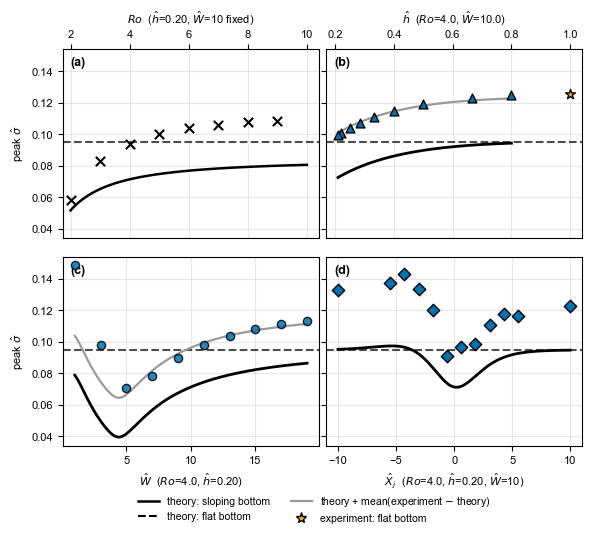

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(AGU_2COL_WIDTH_IN, AGU_2COL_WIDTH_IN * 10.0 / 13),
                          sharey='row', gridspec_kw={'wspace': 0.03})

combo_colors = {(5000,0.2):'#0072B2', (10000,0.2):'#E69F00', (15000,0.2):'#56B4E9',
                 (5000,0.3):'#009E73', (10000,0.3):'#CC79A7'}
SWEEP_MARKERS = {'width': 'o', 'height': '^', 'offset': 'D'}

OFFSET_COLOR = '0.6'   # theory + mean(experiment - theory)
theory_offsets = {}

def add_offset_line(ax, panel, x_th, y_th, xs, ys, x_min=-np.inf):
    """Gray line = theory + mean(experiment - theory), with theory evaluated at each
    experiment's x by interpolating the dense theory curve. Only experiments with
    x >= x_min are used for the mean; the line is drawn over the whole theory curve."""
    xs, ys = np.asarray(xs, float), np.asarray(ys, float)
    keep = xs >= x_min
    if not keep.any():
        return
    off = float(np.mean(ys[keep] - np.interp(xs[keep], x_th, y_th)))
    theory_offsets[panel] = (off, int(keep.sum()))
    ax.plot(x_th, np.asarray(y_th) + off, color=OFFSET_COLOR, linewidth=1.6, zorder=3)

# (a) Ro sweep, set10 (\hat W=10, \hat h=0.2)
RO_MIN_PLOT = 2.0   # lowest Ro with experiments
ro_mask = Ro_dense >= RO_MIN_PLOT
axes[0,0].plot(Ro_dense[ro_mask], Ro_dense_peak[ro_mask], 'k-', linewidth=1.8)
ro_xs, ro_ys = [], []
for t in sets['set10']:
    sh = sigma_hat_exp(t)
    if sh is not None:
        ro_xs.append(test_Ro(t)); ro_ys.append(sh)

if ro_xs:
    axes[0,0].scatter(ro_xs, ro_ys, color='black', marker='x', s=45, linewidths=1.5, zorder=5)
axes[0,0].set_xlabel(rf"$Ro$  ($\hat h$={hs_nd_ref:.2f}, $\hat W$={Ws_nd_ref:.0f} fixed)"); axes[0,0].set_ylabel(r"peak $\hat\sigma$")
axes[0,0].axhline(flat_bottom_sigma, color='k', linestyle='--', linewidth=1.5, alpha=0.7)
axes[0,0].set_xlim(left=RO_MIN_PLOT - 0.25)
axes[0,0].grid(alpha=0.3)

# (b) \hat h sweep, set4 (Ro=4, \hat W=10)
axes[0,1].plot(hs_theory, sig_hs_theory, 'k-', linewidth=2)
xs, ys = [], []
for t in sets['set4']:
    sh = sigma_hat_exp(t)
    if sh is not None:
        xs.append(test_hs_nd(t)); ys.append(sh)
if xs:
    axes[0,1].scatter(xs, ys, color=combo_colors[set_to_combo['set4']], marker=SWEEP_MARKERS['height'],
                       s=40, edgecolor='k', zorder=5)
add_offset_line(axes[0,1], 'b', hs_theory, sig_hs_theory, xs, ys)
flat_xs, flat_ys = [], []
for t in ['test242']:  # flat-bottom control
    sh = sigma_hat_exp(t)
    if sh is not None:
        flat_xs.append(test_hs_nd(t)); flat_ys.append(sh)
if flat_xs:
    axes[0,1].scatter(flat_xs, flat_ys, color='#FFB300', marker='*', s=55, edgecolor='k', zorder=6)
axes[0,1].set_xlabel(rf"$\hat h$  ($Ro$={Ro_set4:.1f}, $\hat W$={Ws_nd_set4:.1f})"); axes[0,1].set_ylabel(r"peak $\hat\sigma$")
axes[0,1].axhline(flat_bottom_sigma, color='k', linestyle='--', linewidth=1.5, alpha=0.7)
axes[0,1].grid(alpha=0.3)

# (c) \hat W sweep, set1 (Ro=4, \hat h=0.2)
axes[1,0].plot(Ws_theory, sig_Ws_theory, 'k-', linewidth=2)
xs, ys = [], []
for t in sets['set1']:
    sh = sigma_hat_exp(t)
    if sh is not None:
        xs.append(test_Ws_nd(t)); ys.append(sh)
if xs:
    axes[1,0].scatter(xs, ys, color=combo_colors[set_to_combo['set1']], marker=SWEEP_MARKERS['width'],
                       s=35, edgecolor='k', alpha=0.85, zorder=5)
WS_MIN_OFFSET = 5.0   # offset line uses experiments with W_hat >= 5
add_offset_line(axes[1,0], 'c', Ws_theory, sig_Ws_theory, xs, ys, x_min=WS_MIN_OFFSET)
axes[1,0].set_xlabel(rf"$\hat W$  ($Ro$={Ro_set4:.1f}, $\hat h$={hs_nd_theory:.2f})"); axes[1,0].set_ylabel(r"peak $\hat\sigma$")
axes[1,0].axhline(flat_bottom_sigma, color='k', linestyle='--', linewidth=1.5, alpha=0.7)
axes[1,0].grid(alpha=0.3)

# (d) jet-centre sweep, set11 (Ro=4, \hat h=0.2, \hat W=10)
# x-axis in L_jet units: \hat X_j = (offset in slope widths) * \hat W
axes[1,1].plot(Xj11_theory * Ws11, sig11_theory, 'k-', linewidth=2)
pts11 = [(set11_offsets[t] * Ws11, sigma_hat_exp(t)) for t in sets_new['set11'] if sigma_hat_exp(t) is not None]
if pts11:
    axes[1,1].scatter(*zip(*pts11), color='#0072B2', marker=SWEEP_MARKERS['offset'], s=40, edgecolor='k', zorder=5)
axes[1,1].set_xlabel(rf"$\hat X_j$  ($Ro$={Ro11:.1f}, $\hat h$={hs11:.2f}, $\hat W$={Ws11:.0f})")
axes[1,1].set_ylabel(r"peak $\hat\sigma$")
axes[1,1].axhline(flat_bottom_sigma, color='k', linestyle='--', linewidth=1.5, alpha=0.7)
axes[1,1].grid(alpha=0.3)

# Same y-range in all four panels
growth_axes = [axes[0,0], axes[0,1], axes[1,0], axes[1,1]]
y_lo = min(ax.get_ylim()[0] for ax in growth_axes)
y_hi = max(ax.get_ylim()[1] for ax in growth_axes)
for ax in growth_axes:
    ax.set_ylim(y_lo, y_hi)

# y-axis only on the left panel of each row
for ax in (axes[0, 1], axes[1, 1]):
    ax.tick_params(labelleft=False)
    ax.set_ylabel('')

# Top row: x-axis on top
for ax in (axes[0, 0], axes[0, 1]): ax.xaxis.tick_top(); ax.xaxis.set_label_position('top')

for ax, label in zip([axes[0,0], axes[0,1], axes[1,0], axes[1,1]], ['a', 'b', 'c', 'd']):
    add_panel_label(ax, label)

# Shared legend below the panels
shared_handles = [
    Line2D([0], [0], color='k', linestyle='-', linewidth=1.8, label='theory: sloping bottom'),
    Line2D([0], [0], color='k', linestyle='--', linewidth=1.5, label='theory: flat bottom'),
    Line2D([0], [0], color=OFFSET_COLOR, linestyle='-', linewidth=1.6,
           label='theory + mean(experiment $-$ theory)'),
    Line2D([0], [0], marker='*', color='none', markerfacecolor='#FFB300', markeredgecolor='k',
           markersize=8, label='experiment: flat bottom'),
]
fig.legend(handles=shared_handles, loc='lower center', ncol=2, bbox_to_anchor=(0.5, -0.06),
           fontsize=7.5, frameon=False)

fig.tight_layout(rect=[0, 0.04, 1, 1])
fig.subplots_adjust(wspace=0.03,
                    hspace=0.10)
save_agu_figure(fig, 'figure_growth_rate_4panel')
for panel, (off, n) in theory_offsets.items():
    print(f"panel ({panel}): mean (experiment - theory) offset = {off:+.4f}  (from {n} experiments)")
plt.show()

---
## Part 7 — Figure 5: dominant wavelength, four panels

Theory wavelength is $\hat\lambda=2\pi/\hat k_{peak}$, where $\hat k_{peak}$ is the wavenumber of maximum
growth. The simulated `dominant_wavelength` (at the peak-growth time) is stored in **km**, so
$\hat\lambda_{exp}=(\lambda_{km}\times1000)/L_{jet,m}$.

In [8]:
def wavelength_hat_exp(test_id):
    """Experimental nondimensional wavelength for a test, or None if unavailable.
    The saved dominant wavelength is in km, so it is converted to metres before dividing by the jet width."""
    if test_id not in peak_results:
        return None
    pw_km = peak_results[test_id]['peak_wavelength']
    if pw_km is None or not np.isfinite(pw_km):
        return None
    _, _, jw, _, _ = experiment_params[test_id]
    return (pw_km * 1000.0) / jw

GROWTH_THRESHOLD = 0.005   # below this peak growth rate the dominant k is meaningless -> NaN wavelength

def theory_wavelength(name):
    """lambda_hat = 2*pi/k_peak for one of the cached theory curves (NaN where growth < threshold)."""
    sig, kpk = theory[name]
    with np.errstate(divide='ignore', invalid='ignore'):
        return np.where((sig >= GROWTH_THRESHOLD) & (kpk > 0), 2 * np.pi / kpk, np.nan)

wl_Ro_theory = theory_wavelength('Ro')      # on Ro_dense
wl_hs_theory = theory_wavelength('hs')      # on hs_theory
wl_Ws_theory = theory_wavelength('Ws')      # on Ws_theory
wl11_theory  = theory_wavelength('Xj11')    # on Xj11_theory
flat_bottom_wavelength = float(theory_wavelength('flat')[0])

n_wl_available = sum(1 for t in experiment_params if wavelength_hat_exp(t) is not None)
print(f"experimental wavelength available for {n_wl_available}/{len(experiment_params)} tests")
print(f"flat-bottom theory wavelength: {flat_bottom_wavelength:.3f} (Ro-, Ws_nd- and offset-independent)")

experimental wavelength available for 111/112 tests
flat-bottom theory wavelength: 14.128 (Ro-, Ws_nd- and offset-independent)


/jobfs/182289408.gadi-pbs/ipykernel_517510/2774284523.py:113: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(rect=[0, 0.04, 1, 1])


Saved figures/figure_wavelength_4panel.pdf and figures/figure_wavelength_4panel.png


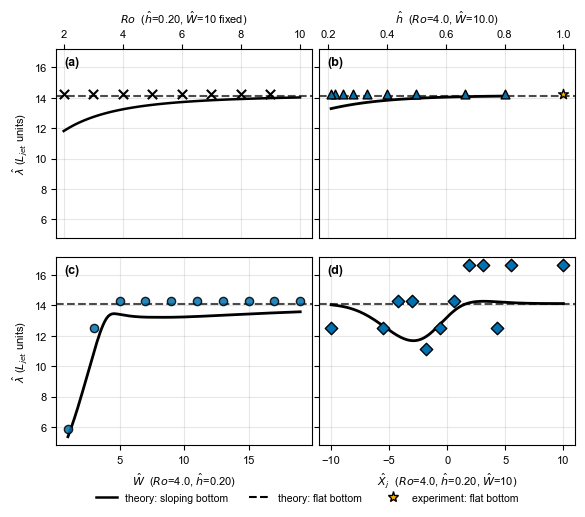

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(AGU_2COL_WIDTH_IN, AGU_2COL_WIDTH_IN * 10.0 / 13),
                          sharey='row', gridspec_kw={'wspace': 0.03})

combo_colors = {(5000,0.2):'#0072B2', (10000,0.2):'#E69F00', (15000,0.2):'#56B4E9',
                 (5000,0.3):'#009E73', (10000,0.3):'#CC79A7'}
SWEEP_MARKERS = {'width': 'o', 'height': '^', 'offset': 'D'}

# (a) Ro sweep, set10 (\hat W=10, \hat h=0.2)
RO_MIN_PLOT = 2.0   # lowest Ro with experiments
ro_mask = Ro_dense >= RO_MIN_PLOT
axes[0,0].plot(Ro_dense[ro_mask], wl_Ro_theory[ro_mask], 'k-', linewidth=1.8)
ro_xs, ro_ys = [], []
for t in sets['set10']:
    wl = wavelength_hat_exp(t)
    if wl is not None:
        ro_xs.append(test_Ro(t)); ro_ys.append(wl)

if ro_xs:
    axes[0,0].scatter(ro_xs, ro_ys, color='black', marker='x', s=45, linewidths=1.5, zorder=5)
axes[0,0].set_xlabel(rf"$Ro$  ($\hat h$={hs_nd_ref:.2f}, $\hat W$={Ws_nd_ref:.0f} fixed)")
axes[0,0].set_ylabel(r"$\hat\lambda$ ($L_{jet}$ units)")
axes[0,0].axhline(flat_bottom_wavelength, color='k', linestyle='--', linewidth=1.5, alpha=0.7)
axes[0,0].set_xlim(left=RO_MIN_PLOT - 0.25)
axes[0,0].grid(alpha=0.3)

# (b) \hat h sweep, set4
axes[0,1].plot(hs_theory, wl_hs_theory, 'k-', linewidth=2)
xs, ys = [], []
for t in sets['set4']:
    wl = wavelength_hat_exp(t)
    if wl is not None:
        xs.append(test_hs_nd(t)); ys.append(wl)
if xs:
    axes[0,1].scatter(xs, ys, color=combo_colors[set_to_combo['set4']], marker=SWEEP_MARKERS['height'],
                       s=40, edgecolor='k', zorder=5)
flat_xs, flat_ys = [], []
for t in ['test242']:  # flat-bottom control
    wl = wavelength_hat_exp(t)
    if wl is not None:
        flat_xs.append(test_hs_nd(t)); flat_ys.append(wl)
if flat_xs:
    axes[0,1].scatter(flat_xs, flat_ys, color='#FFB300', marker='*', s=55, edgecolor='k', zorder=6)
axes[0,1].set_xlabel(rf"$\hat h$  ($Ro$={Ro_set4:.1f}, $\hat W$={Ws_nd_set4:.1f})")
axes[0,1].set_ylabel(r"$\hat\lambda$ ($L_{jet}$ units)")
axes[0,1].axhline(flat_bottom_wavelength, color='k', linestyle='--', linewidth=1.5, alpha=0.7)
axes[0,1].grid(alpha=0.3)

# (c) \hat W sweep, set1
axes[1,0].plot(Ws_theory, wl_Ws_theory, 'k-', linewidth=2)
xs, ys = [], []
for t in sets['set1']:
    wl = wavelength_hat_exp(t)
    if wl is not None:
        xs.append(test_Ws_nd(t)); ys.append(wl)
if xs:
    axes[1,0].scatter(xs, ys, color=combo_colors[set_to_combo['set1']], marker=SWEEP_MARKERS['width'],
                       s=35, edgecolor='k', alpha=0.85, zorder=5)
axes[1,0].set_xlabel(rf"$\hat W$  ($Ro$={Ro_set4:.1f}, $\hat h$={hs_nd_theory:.2f})")
axes[1,0].set_ylabel(r"$\hat\lambda$ ($L_{jet}$ units)")
axes[1,0].axhline(flat_bottom_wavelength, color='k', linestyle='--', linewidth=1.5, alpha=0.7)
axes[1,0].grid(alpha=0.3)

# (d) jet-centre sweep, set11
# x-axis in L_jet units: \hat X_j = (offset in slope widths) * \hat W
axes[1,1].plot(Xj11_theory * Ws11, wl11_theory, 'k-', linewidth=2)
pts11 = [(set11_offsets[t] * Ws11, wavelength_hat_exp(t)) for t in sets_new['set11'] if wavelength_hat_exp(t) is not None]
if pts11: axes[1,1].scatter(*zip(*pts11), color='#0072B2', marker=SWEEP_MARKERS['offset'], s=40, edgecolor='k', zorder=5)
axes[1,1].set_xlabel(rf"$\hat X_j$  ($Ro$={Ro11:.1f}, $\hat h$={hs11:.2f}, $\hat W$={Ws11:.0f})")
axes[1,1].set_ylabel(r"$\hat\lambda$ ($L_{jet}$ units)")
axes[1,1].axhline(flat_bottom_wavelength, color='k', linestyle='--', linewidth=1.5, alpha=0.7)
axes[1,1].grid(alpha=0.3)

# Same y-range in all four panels
wavelength_axes = [axes[0,0], axes[0,1], axes[1,0], axes[1,1]]
y_lo = min(ax.get_ylim()[0] for ax in wavelength_axes)
y_hi = max(ax.get_ylim()[1] for ax in wavelength_axes)
for ax in wavelength_axes:
    ax.set_ylim(y_lo, y_hi)

# y-axis only on the left panel of each row
for ax in (axes[0, 1], axes[1, 1]):
    ax.tick_params(labelleft=False)
    ax.set_ylabel('')

# Top row: x-axis on top
for ax in (axes[0, 0], axes[0, 1]): ax.xaxis.tick_top(); ax.xaxis.set_label_position('top')
for ax, label in zip([axes[0,0], axes[0,1], axes[1,0], axes[1,1]], ['a', 'b', 'c', 'd']):
    add_panel_label(ax, label)

shared_handles = [
    Line2D([0], [0], color='k', linestyle='-', linewidth=1.8, label='theory: sloping bottom'),
    Line2D([0], [0], color='k', linestyle='--', linewidth=1.5, label='theory: flat bottom'),
    Line2D([0], [0], marker='*', color='none', markerfacecolor='#FFB300', markeredgecolor='k',
           markersize=8, label='experiment: flat bottom'),
]
fig.legend(handles=shared_handles, loc='lower center', ncol=3, bbox_to_anchor=(0.5, -0.02),
           fontsize=7.5, frameon=False)

fig.tight_layout(rect=[0, 0.04, 1, 1])
fig.subplots_adjust(wspace=0.03,
                    hspace=0.10)
save_agu_figure(fig, 'figure_wavelength_4panel')
plt.show()

---
## Part 14 — Data-completeness check

Two checks, both comparing a "found" timestep against the length of that experiment's own record:

1. **Growth-rate peak**: `peak_tidx` is the `argmax` of the growth rate from the test's reference time
   `idx0` to `t_end=4000`. If it lands at (or within `WALL_TOL` of) the smaller of `t_end` and the
   record's end, the growth rate was still rising and the peak is not a genuine interior peak.
2. **Lifetime end**: `lifetime_end_time_idx` is the last timestep (scanning forward from `peak_tidx`)
   where the dominant wavelength still matches the peak-growth wavelength. If it lands at the end of the
   wavelength record, the lifetime is only a lower bound.

Every test flagged by either check goes into `INCOMPLETE_TESTS`, and Part 16 drops those tests.

In [10]:
WALL_TOL = 3

PEAK_SEARCH_TEND = 4000   # search starts at each test's idx0 (peak_search_start, Part 0)

growth_peak_wall_hits = []
lifetime_wall_hits    = []

for test in all_growth_rates:
    gr_da = all_growth_rates[test]
    gr_max_tidx = int(gr_da.time_idx.max()) if gr_da.size > 0 else None

    # 1. Did the growth-rate peak hit the search window or the end of the record?
    if gr_max_tidx is not None:
        window = gr_da.sel(time_idx=slice(peak_search_start(test), PEAK_SEARCH_TEND))
        if window.size > 0 and not window.isnull().all():
            peak_pos  = int(window.fillna(-np.inf).argmax(dim='time_idx'))
            peak_tidx = int(window.time_idx.values[peak_pos])
            boundary  = min(PEAK_SEARCH_TEND, gr_max_tidx)
            if peak_tidx >= boundary - WALL_TOL:
                growth_peak_wall_hits.append((test, peak_tidx, boundary, gr_max_tidx))

    # 2. Did the lifetime end hit the end of the record?
    wl_da = all_dominant_wavelengths.get(test)
    idx_lifetime_end = all_lifetime_end_time_idx.get(test)
    if wl_da is not None and wl_da.size > 0 and idx_lifetime_end is not None:
        wl_max_tidx = int(wl_da.time_idx.max())
        if idx_lifetime_end >= wl_max_tidx - WALL_TOL:
            lifetime_wall_hits.append((test, idx_lifetime_end, wl_max_tidx))

n_total = len(all_growth_rates)

print(f"=== Growth-rate peak: hit the window/record boundary ===")
print(rf"{len(growth_peak_wall_hits)}/{n_total} tests -- growth rate was still rising when the search stopped\n")
print(f"{'test':<10}{'peak_tidx':<12}{'boundary':<12}{'record_end':<12}")
for t, pt, b, re in sorted(growth_peak_wall_hits):
    print(f"{t:<10}{pt:<12}{b:<12}{re:<12}")

print()
print(f"=== Lifetime end: hit the record's end ===")
print(rf"{len(lifetime_wall_hits)}/{n_total} tests -- the eddy's wavelength was still matching when the simulation ended\n")
print(f"{'test':<10}{'lifetime_end':<14}{'record_end':<12}")
for t, le, re in sorted(lifetime_wall_hits):
    print(f"{t:<10}{le:<14}{re:<12}")

# Filter used by Part 16
INCOMPLETE_TESTS = ({t for t, *_ in growth_peak_wall_hits} |
                    {t for t, *_ in lifetime_wall_hits})

print()
print(f"=== {len(INCOMPLETE_TESTS)} test(s) will be EXCLUDED from Part 16 ===")
print(", ".join(sorted(INCOMPLETE_TESTS)) if INCOMPLETE_TESTS else "(none)")

# Cross-check against the flags saved in the NetCDF file (if present)
if all_growth_peak_hit_wall or all_lifetime_hit_wall:
    flagged_09 = ({t for t, v in all_growth_peak_hit_wall.items() if v} |
                  {t for t, v in all_lifetime_hit_wall.items() if v})
    only_here, only_09 = INCOMPLETE_TESTS - flagged_09, flagged_09 - INCOMPLETE_TESTS
    if only_here or only_09:
        print("note: differs from notebook 09's saved flags -- "
              f"flagged only here: {sorted(only_here) or '-'}; only in notebook 09: {sorted(only_09) or '-'}")
    else:
        print("matches notebook 09's saved growth_peak_hit_wall / lifetime_hit_wall flags")

=== Growth-rate peak: hit the window/record boundary ===
3/113 tests -- growth rate was still rising when the search stopped\n
test      peak_tidx   boundary    record_end  
test185   3623        3623        3623        
test186   3623        3623        3623        
test187   3623        3623        3623        

=== Lifetime end: hit the record's end ===
20/113 tests -- the eddy's wavelength was still matching when the simulation ended\n
test      lifetime_end  record_end  
test173   3623          3623        
test176   3623          3623        
test177   3623          3623        
test178   3623          3623        
test184   3623          3623        
test185   3623          3623        
test186   3623          3623        
test187   3623          3623        
test188   3623          3623        
test189   3623          3623        
test206   4343          4343        
test207   4343          4343        
test220   1415          1415        
test222   1415          1415        
t

---
## Part 16 — Figure 6: pooled comparison with least-squares fits and confidence intervals

All experiments in `sets` plus `set11` (the $\hat X_j$ sweep at $\hat W=10$), **except the tests flagged in
Part 14** (`INCOMPLETE_TESTS`). `set8` is not used (it duplicates `set11` at $\hat W=11$). Only one
flat-bottom control is kept, `test242` ($Ro=4$); `test243` is dropped (`DROP_TESTS`).

Theory values for each test come from the same calculation as Parts 6 and 7, evaluated at that test's
own $Ro$, $\hat h$, $\hat W$ and jet offset.

- **(a) Growth rate:** $\hat\sigma_{sim} = a + b\,\hat\sigma_{th}$, with the bias (mean simulation − theory) and RMSE.
- **(b) Wavelength:** $\hat\lambda_{sim} = a + b\,\hat\lambda_{th}$, the same statistics, plus the percentage of runs within ±20% of theory.
- **(c) Lifetime:** least-squares fit in log–log space, $\ln\hat T_{life} = \ln A + b\,\ln(1/\hat\sigma)$, i.e.
  $\hat T_{life} = A\,(1/\hat\sigma)^b$.

**Confidence intervals** come from a cluster bootstrap (5000 resamples) that resamples whole experiment
groups (`set`), because runs within a sweep share a reference geometry and are not independent.

**Units.** $\hat T_{life}$ = lifetime (hourly steps $\times$ 3600 s) $\times\,U_0/L_{jet}$.

In [11]:
# Part 16.0 -- experiment-group colours/labels and per-test theory
combo_colors = {(5000,0.2):'#0072B2', (10000,0.2):'#E69F00', (15000,0.2):'#56B4E9',
                 (5000,0.3):'#009E73', (10000,0.3):'#CC79A7'}

SWEEP_TYPE_ALL = {
    'set1': 'width', 'set2': 'width', 'set3': 'width', 'set6': 'width', 'set7': 'width',
    'set4': 'height', 'set5': 'height',
    'set8': 'offset',
    'set9': 'ro',
    'set10': 'ro',
    'set_flat': 'flat',   # flat-bottom controls
}
SWEEP_MARKERS_ALL = {'width': 'o', 'height': '^', 'offset': 'D', 'ro': 'x', 'flat': '*'}
FLAT_COLOR = '#FFB300'

# Groups used in Part 16: `sets` plus set11
SETS_P16 = {**sets, **sets_new}
SETS_P16.pop('set8', None)   # set8 duplicates set11
SWEEP_TYPE_ALL['set11'] = 'offset'
set_to_combo['set11'] = (5000, 0.2)
SET11_COLOR = combo_colors[(5000, 0.2)]     # Ro = 4 blue

def group_color_label(set_name, tests):
    """Colour and held-parameter label for an experiment group."""
    sweep = SWEEP_TYPE_ALL[set_name]
    if sweep == 'ro':
        if set_name == 'set9':
            return 'black', r"$Ro$=2-10, $\hat h$=0.20, $\hat W$=1.00 (clean sweep, test245-253)"
        return 'dimgray', r"$Ro$=3-10,20, $\hat h$=0.20, $\hat W$=10.00 (sweep, test254-262)"
    if sweep == 'flat':
        return FLAT_COLOR, r"flat bottom, no topography ($\hat h$=1, test242-243)"
    combo = set_to_combo[set_name]
    ro_val = combo[1] / (F_CORIOLIS * combo[0])
    color = combo_colors.get(combo, '#888888')
    if sweep == 'width':      # \hat h fixed, \hat W is the swept quantity
        hs_val = test_hs_nd(tests[0])
        label = rf"$Ro$={ro_val:.2g}, $\hat h$={hs_val:.2f} ($\hat W$ varies)"
    elif sweep == 'height':   # \hat W fixed, \hat h is the swept quantity
        ws_val = test_Ws_nd(tests[0])
        label = rf"$Ro$={ro_val:.2g}, $\hat W$={ws_val:.1f} ($\hat h$ varies)"
    else:                     # offset: both \hat h, \hat W fixed, \hat X_j is swept
        hs_val = test_hs_nd(tests[0]); ws_val = test_Ws_nd(tests[0])
        label = rf"$Ro$={ro_val:.2g}, $\hat h$={hs_val:.2f}, $\hat W$={ws_val:.1f} ($\hat X_j$ varies)"
    return color, label

group_info = {}   # set_name -> (color, label, marker)
for set_name, tests in SETS_P16.items():
    color, label = group_color_label(set_name, tests)
    if set_name == 'set11':
        color = SET11_COLOR
    group_info[set_name] = (color, label, SWEEP_MARKERS_ALL[SWEEP_TYPE_ALL[set_name]])

# Theory at every test's own geometry (same peak_growth as Parts 6/7), cached
PER_TEST_CACHE = os.path.join(FIGURE_DIR, 'part16_theory_per_test.npz')
JET_OFFSETS = {**set8_offsets, **set11_offsets}      # slope-width units; 0 for every other test

def test_theory_args(t):
    Ws = test_Ws_nd(t)
    return (test_Ro(t), JET_OFFSETS.get(t, 0.0) * Ws, test_hs_nd(t), 0.0, Ws)

all_tests = [t for tests in SETS_P16.values() for t in tests]
pt_args = [test_theory_args(t) for t in all_tests]
pt_key = repr((DX_THEORY, DX_SCAN, N_CAP_THEORY, K_SCAN.tolist(), K_LOCAL_HALF, K_LOCAL_STEP,
               all_tests, np.round(np.array(pt_args), 10).tolist()))

pt = None
if not FORCE_RECOMPUTE and os.path.exists(PER_TEST_CACHE):
    with np.load(PER_TEST_CACHE, allow_pickle=False) as z:
        if str(z['key']) == pt_key:
            pt = np.column_stack([z['sig'], z['k']])
            print(f"loaded per-test theory from {PER_TEST_CACHE}")
if pt is None:
    t0 = time.time()
    pt = np.array(peak_growth_many(pt_args))
    np.savez(PER_TEST_CACHE, key=np.array(pt_key), sig=pt[:, 0], k=pt[:, 1])
    print(f"computed per-test theory for {len(all_tests)} tests in {time.time() - t0:.0f} s "
          f"(saved to {PER_TEST_CACHE})")
THEORY_PER_TEST = {t: (float(s), float(k)) for t, (s, k) in zip(all_tests, pt)}

def sigma_hat_theory(test_id):
    """Theory peak growth rate at this test's own geometry (high resolution)."""
    return THEORY_PER_TEST[test_id][0] if test_id in THEORY_PER_TEST else None

def lambda_hat_theory(test_id):
    """Theory dominant wavelength 2*pi/k_peak at this test's own geometry; None where the
    theory growth rate is below GROWTH_THRESHOLD (dominant k meaningless there)."""
    if test_id not in THEORY_PER_TEST:
        return None
    s, k = THEORY_PER_TEST[test_id]
    if s < GROWTH_THRESHOLD or not np.isfinite(k) or k <= 0:
        return None
    return 2 * np.pi / k

loaded per-test theory from figures/part16_theory_per_test.npz


In [12]:
# Part 16.1 -- assemble one tidy table (one row per usable experiment)
import pandas as pd

GROWTH_THRESHOLD = 0.005 # theory sigma_hat below this = negligible growth

def lifetime_hat_exp_si(test_id):
    r"""Nondimensional lifetime T_hat = T[s] * U0/Ljet[s^-1] (alias for lifetime_hat_exp)."""
    return lifetime_hat_exp(test_id)

# Only one flat-bottom control is kept: test242 (Ro = 4)
DROP_TESTS = {'test243'}

# Part 14 completeness filter
_excluded = set(INCOMPLETE_TESTS)

rows = []
for set_name, tests in SETS_P16.items():
    for t in tests:
        if t in _excluded or t in DROP_TESTS:
            continue
        sig_ex = sigma_hat_exp(t)
        if sig_ex is None:
            continue
        sig_th = sigma_hat_theory(t)
        lam_th = lambda_hat_theory(t)
        lam_ex = wavelength_hat_exp(t)
        rows.append(dict(
            test=t, set=set_name, sweep=SWEEP_TYPE_ALL[set_name],
            sig_th=sig_th, sig_ex=sig_ex,
            lam_th=lam_th, lam_ex=lam_ex,
            T_hat=lifetime_hat_exp_si(t),
            inv_sig=1.0 / sig_ex if sig_ex else np.nan,
        ))

df = pd.DataFrame(rows, columns=['test', 'set', 'sweep', 'sig_th', 'sig_ex', 'lam_th', 'lam_ex',
                                 'T_hat', 'inv_sig']).set_index('test')
df = df.astype({c: float for c in ['sig_th', 'sig_ex', 'lam_th', 'lam_ex',
                                   'T_hat', 'inv_sig']})

excluded_here = sorted(t for tests in SETS_P16.values() for t in tests if t in _excluded)
print(f"{len(df)} experiments in the table; {sorted(DROP_TESTS)} dropped; "
      f"{len(excluded_here)} excluded by the Part 14 check: {', '.join(excluded_here) or '(none)'}")
print(f"theory predicts negligible growth (sigma_th < {GROWTH_THRESHOLD}) for: "
      f"{list(df.index[df['sig_th'] < GROWTH_THRESHOLD])}")

78 experiments in the table; ['test243'] dropped; 20 excluded by the Part 14 check: test173, test176, test177, test178, test184, test185, test186, test187, test188, test189, test206, test207, test220, test222, test223, test224, test225, test226, test227, test254
theory predicts negligible growth (sigma_th < 0.005) for: ['test174', 'test175']


In [13]:
# Part 16.2 -- agreement statistics, pooled and per group
if df.empty:
    print('No experiments in the table -- statistics skipped (run Part 0 with access to the NetCDF data).')
else:
    from scipy.stats import spearmanr

    N_BOOT = 5000
    RNG = np.random.default_rng(12345)
    REL_TOL = 0.20   # "within +/-20% of theory" for the wavelength comparison

    def line_fit(x, y):
        """Ordinary least squares y = a + b*x. Returns (slope b, intercept a)."""
        b, a = np.polyfit(np.asarray(x, float), np.asarray(y, float), 1)
        return float(b), float(a)

    def cluster_boot(d, func, group_col='set', n_boot=N_BOOT):
        """Bootstrap by resampling whole experiment GROUPS (sweeps) with replacement --
        runs within a sweep share a reference geometry and are not independent.
        Returns an array of func(sample) over the resamples."""
        groups = d[group_col].unique()
        parts = {g: d[d[group_col] == g] for g in groups}
        out = []
        for _ in range(n_boot):
            pick = RNG.choice(groups, size=len(groups), replace=True)
            sample = pd.concat([parts[g] for g in pick])
            try:
                v = func(sample)
                if np.all(np.isfinite(v)):
                    out.append(v)
            except Exception:
                pass
        return np.array(out)

    def ci95(samples):
        return np.percentile(samples, [2.5, 97.5], axis=0)

    def fit_with_ci(d, xcol, ycol, x_grid):
        """Line fit + cluster-bootstrap 95% CIs for slope, intercept, and the fitted
        line itself (pointwise band over x_grid)."""
        b, a = line_fit(d[xcol], d[ycol])
        boots = cluster_boot(d, lambda s: np.array(line_fit(s[xcol], s[ycol])))
        lines = boots[:, 1][:, None] + boots[:, 0][:, None] * x_grid[None, :]
        return dict(slope=b, intercept=a,
                    slope_ci=ci95(boots[:, 0]), intercept_ci=ci95(boots[:, 1]),
                    r2=float(np.corrcoef(d[xcol], d[ycol])[0, 1] ** 2),
                    x_grid=x_grid, band=ci95(lines))

    def agreement(d, xcol, ycol):
        diff = d[ycol] - d[xcol]
        return dict(n=len(d), bias=float(diff.mean()),
                    bias_ci=ci95(cluster_boot(d, lambda s: float((s[ycol] - s[xcol]).mean()))),
                    rmse=float(np.sqrt((diff ** 2).mean())))

    def loglog_slope(x, y):
        return float(np.polyfit(np.log(x), np.log(y), 1)[0])

    def safe_spearman(x, y):
        x, y = np.asarray(x), np.asarray(y)
        if len(x) < 4 or np.ptp(x) == 0 or np.ptp(y) == 0:
            return np.nan
        return spearmanr(x, y).correlation

    # Subsets
    dA = df.dropna(subset=['sig_th', 'sig_ex'])
    dB = df.dropna(subset=['lam_th', 'lam_ex']).copy()
    dB['rel_err'] = (dB['lam_ex'] - dB['lam_th']) / dB['lam_th']
    dC = df.dropna(subset=['T_hat', 'inv_sig'])
    dC = dC[(dC['T_hat'] > 0) & (dC['inv_sig'] > 0)]
    dC = dC.assign(log_x=np.log(dC['inv_sig']), log_y=np.log(dC['T_hat']))

    # (a) growth rate
    gridA = np.linspace(0, 1.08 * max(dA['sig_th'].max(), dA['sig_ex'].max()), 100)
    fitA = fit_with_ci(dA, 'sig_th', 'sig_ex', gridA)
    agA = agreement(dA, 'sig_th', 'sig_ex')

    # (b) wavelength, plus fraction within +/-20%
    gridB = np.linspace(0, 1.08 * max(dB['lam_th'].max(), dB['lam_ex'].max()), 100)
    fitB = fit_with_ci(dB, 'lam_th', 'lam_ex', gridB)
    agB = agreement(dB, 'lam_th', 'lam_ex')
    agB['within'] = float((dB['rel_err'].abs() <= REL_TOL).mean())
    agB['within_ci'] = ci95(cluster_boot(dB, lambda s: float((s['rel_err'].abs() <= REL_TOL).mean())))
    agB['median_rel_err'] = float(dB['rel_err'].median())

    # (c) lifetime: power law T_hat = A * (1/sigma_hat)^b, fitted in log-log space
    gridC = np.geomspace(dC['inv_sig'].min() / 1.15, dC['inv_sig'].max() * 1.15, 100)
    fitC = fit_with_ci(dC, 'log_x', 'log_y', np.log(gridC))
    fitC['A'] = float(np.exp(fitC['intercept']))
    fitC['n'] = len(dC)

    # Per-group statistics
    per_rows = []
    for set_name in SETS_P16:
        a = dA[dA['set'] == set_name]; b = dB[dB['set'] == set_name]; c = dC[dC['set'] == set_name]
        if len(a) == 0 and len(b) == 0 and len(c) == 0:
            continue
        per_rows.append(dict(
            set=set_name,
            label=group_info[set_name][1] if 'group_info' in globals() else set_name,
            n=len(a),
            sigma_bias=float((a['sig_ex'] - a['sig_th']).mean()) if len(a) else np.nan,
            sigma_rho=safe_spearman(a['sig_th'], a['sig_ex']),
            lambda_bias=float((b['lam_ex'] - b['lam_th']).mean()) if len(b) else np.nan,
            lambda_within20_pct=100 * float((b['rel_err'].abs() <= REL_TOL).mean()) if len(b) else np.nan,
        ))
    stats_table = pd.DataFrame(per_rows).set_index('set')

    # Report
    def _fmt_fit(f, nd=3):
        return (f"slope = {f['slope']:.{nd}f} [95% CI {f['slope_ci'][0]:.{nd}f}, {f['slope_ci'][1]:.{nd}f}], "
                f"intercept = {f['intercept']:.{nd}f} [{f['intercept_ci'][0]:.{nd}f}, {f['intercept_ci'][1]:.{nd}f}], "
                f"R^2 = {f['r2']:.2f}")

    print("(a) GROWTH RATE  sigma_sim = a + b * sigma_theory")
    print("    " + _fmt_fit(fitA, 3))
    print(f"    n = {agA['n']},  bias = {agA['bias']:+.4f} [{agA['bias_ci'][0]:+.4f}, {agA['bias_ci'][1]:+.4f}],  "
          f"RMSE = {agA['rmse']:.4f}")
    print("(b) WAVELENGTH  lambda_sim = a + b * lambda_theory")
    print("    " + _fmt_fit(fitB, 2))
    print(f"    n = {agB['n']},  bias = {agB['bias']:+.2f} [{agB['bias_ci'][0]:+.2f}, {agB['bias_ci'][1]:+.2f}] L_jet,  "
          f"RMSE = {agB['rmse']:.2f} L_jet")
    print(f"    within +/-{100*REL_TOL:.0f}% of theory: {100*agB['within']:.0f}% "
          f"[{100*agB['within_ci'][0]:.0f}-{100*agB['within_ci'][1]:.0f}%],  "
          f"median relative error = {100*agB['median_rel_err']:+.0f}%")
    print("(c) LIFETIME  log T_hat = log A + b * log(1/sigma_hat)")
    print("    " + _fmt_fit(fitC, 2) + f"   (A = exp(intercept) = {fitC['A']:.2f})")
    print(f"    n = {fitC['n']}")
    print()
    with pd.option_context('display.width', 200, 'display.max_columns', 20):
        print(stats_table.round(3).drop(columns='label'))

    os.makedirs(FIGURE_DIR, exist_ok=True)
    df.to_csv(os.path.join(FIGURE_DIR, 'pooled_comparison_per_test.csv'))
    stats_table.to_csv(os.path.join(FIGURE_DIR, 'pooled_comparison_stats.csv'))
    print(f"\nSaved per-test data and per-group stats to {FIGURE_DIR}/")

(a) GROWTH RATE  sigma_sim = a + b * sigma_theory
    slope = 0.621 [95% CI 0.451, 0.879], intercept = 0.069 [0.049, 0.079], R^2 = 0.41
    n = 78,  bias = +0.0419 [+0.0336, +0.0525],  RMSE = 0.0460
(b) WAVELENGTH  lambda_sim = a + b * lambda_theory
    slope = 1.02 [95% CI 0.92, 1.11], intercept = 0.72 [-0.18, 2.20], R^2 = 0.88
    n = 76,  bias = +0.96 [+0.51, +1.65] L_jet,  RMSE = 1.72 L_jet
    within +/-20% of theory: 79% [57-93%],  median relative error = +6%
(c) LIFETIME  log T_hat = log A + b * log(1/sigma_hat)
    slope = 1.19 [95% CI 0.76, 1.74], intercept = 1.76 [0.58, 2.73], R^2 = 0.49   (A = exp(intercept) = 5.78)
    n = 78

           n  sigma_bias  sigma_rho  lambda_bias  lambda_within20_pct
set                                                                  
set1      10       0.032      0.806        0.933              100.000
set2       6       0.061      0.714        2.073               50.000
set3       4       0.070      0.800        1.243                0.000
set

Saved figures/figure_combined_summary_v2.pdf and figures/figure_combined_summary_v2.png


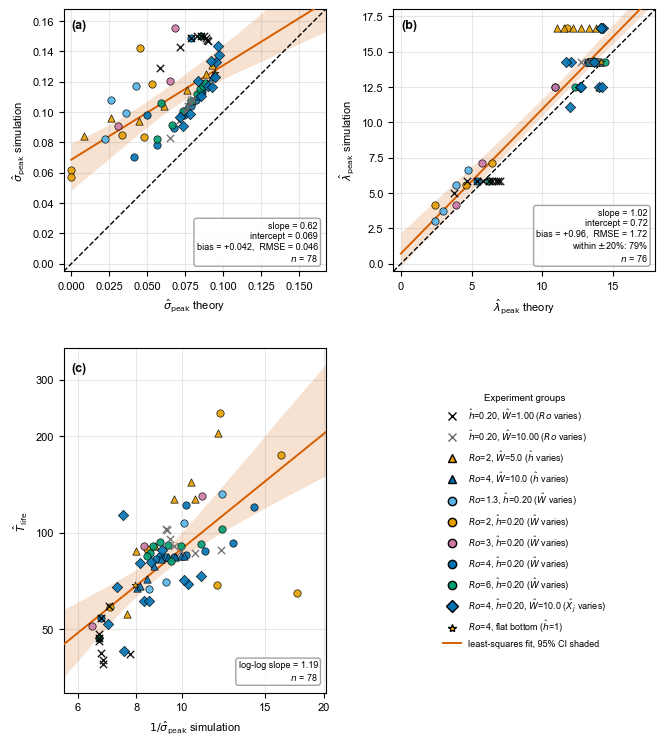

CAPTION NUMBERS
(a) slope 0.62 (95% CI 0.45--0.88), intercept 0.069 (0.049--0.079)
(b) slope 1.02 (0.92--1.11), intercept 0.72 (-0.18--2.20), within +/-20%: 79% (57--93%)
(c) log-log slope 1.19 (0.76--1.74), intercept 1.76 (0.58--2.73), A = 5.78


In [14]:
# Part 16.3 -- summary figure (CIs for the caption are printed at the end of this cell)
if df.empty:
    print('No experiments in the table -- figure skipped (run Part 0 with access to the NetCDF data).')
else:
    import re
    from matplotlib.lines import Line2D
    from matplotlib.ticker import FixedLocator, NullLocator, FuncFormatter

    FIT_COLOR = '#D55E00'
    BAND_ALPHA = 0.18
    BOX = dict(boxstyle='round', facecolor='white', edgecolor='0.6', alpha=0.9)

    def _clean_label(label):
        """Legend labels without internal test IDs or 'no topography'."""
        label = re.sub(r',?\s*test\d+(-\d+)?', '', label)
        label = label.replace('(clean sweep)', r'($Ro$ varies)').replace('(sweep)', r'($Ro$ varies)')
        if r'($Ro$ varies)' in label:
            label = re.sub(r'^\$Ro\$=.*?,\s*(?=\$)', '', label)
        if 'flat bottom' in label:
            label = r"$Ro$=4, flat bottom ($\hat h$=1)"
        return label

    def _scatter_groups(ax, d, xcol, ycol):
        for set_name in SETS_P16:
            s = d[d['set'] == set_name]
            if s.empty:
                continue
            color, _, marker = group_info[set_name]
            filled = marker not in ('x', '+', '1', '2', '3', '4')
            kw = dict(edgecolor='k', linewidths=0.5) if filled else dict(linewidths=1.0)
            ax.scatter(s[xcol], s[ycol], color=color, marker=marker, s=28, alpha=0.9, zorder=5, **kw)

    def _fit_panel(ax, d, xcol, ycol, fit, ag, nd, extra_lines=()):
        _scatter_groups(ax, d, xcol, ycol)
        hi_lim = fit['x_grid'][-1]
        pad = 0.03 * hi_lim
        ax.plot([-pad, hi_lim], [-pad, hi_lim], 'k--', lw=1.0, zorder=3)          # 1:1
        ax.fill_between(fit['x_grid'], fit['band'][0], fit['band'][1],
                        color=FIT_COLOR, alpha=BAND_ALPHA, lw=0, zorder=2)
        ax.plot(fit['x_grid'], fit['intercept'] + fit['slope'] * fit['x_grid'], '-',
                color=FIT_COLOR, lw=1.4, zorder=4)
        ax.set_xlim(-pad, hi_lim); ax.set_ylim(-pad, hi_lim); ax.set_aspect('equal', adjustable='box')
        lines = [f"slope = {fit['slope']:.2f}",
                 f"intercept = {fit['intercept']:.{nd}f}",
                 f"bias = {ag['bias']:+.{nd}f},  RMSE = {ag['rmse']:.{nd}f}",
                 *extra_lines,
                 f"$n$ = {ag['n']}"]
        ax.text(0.97, 0.03, "\n".join(lines), transform=ax.transAxes, ha='right', va='bottom',
                fontsize=6.5, bbox=BOX, zorder=8)
        ax.grid(alpha=0.3)

    def _log_ticks(axis, lo, hi, candidates=(2, 3, 4, 5, 6, 8, 10, 12, 15, 20, 30, 50, 100, 200, 300, 500, 1000)):
        """Plain-number ticks on a log axis, only at values inside the limits."""
        ticks, min_gap = [], np.log10(hi / lo) / 7      # at most ~7 evenly spread labels
        for t in candidates:
            if lo <= t <= hi and (not ticks or np.log10(t / ticks[-1]) >= min_gap):
                ticks.append(t)
        axis.set_major_locator(FixedLocator(ticks))
        axis.set_minor_locator(NullLocator())
        axis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:g}"))

    fig, axes = plt.subplots(2, 2, figsize=(AGU_2COL_WIDTH_IN, AGU_2COL_WIDTH_IN * 13 / 11))

    # (a) growth rate
    ax = axes[0, 0]
    _fit_panel(ax, dA, 'sig_th', 'sig_ex', fitA, agA, nd=3)
    ax.set_xlabel(r"$\hat\sigma_{\mathrm{peak}}$ theory")
    ax.set_ylabel(r"$\hat\sigma_{\mathrm{peak}}$ simulation")
    add_panel_label(ax, 'a')

    # (b) wavelength
    ax = axes[0, 1]
    _fit_panel(ax, dB, 'lam_th', 'lam_ex', fitB, agB, nd=2,
               extra_lines=(f"within $\\pm${100*REL_TOL:.0f}%: {100*agB['within']:.0f}%",))
    ax.set_xlabel(r"$\hat\lambda_{\mathrm{peak}}$ theory")
    ax.set_ylabel(r"$\hat\lambda_{\mathrm{peak}}$ simulation")
    add_panel_label(ax, 'b')

    # (c) lifetime vs growth timescale: least-squares fit in log-log space
    ax = axes[1, 0]
    _scatter_groups(ax, dC, 'inv_sig', 'T_hat')
    xx = fitC['x_grid']                                   # log(1/sigma) grid
    ax.fill_between(np.exp(xx), np.exp(fitC['band'][0]), np.exp(fitC['band'][1]),
                    color=FIT_COLOR, alpha=BAND_ALPHA, lw=0, zorder=2)
    ax.plot(np.exp(xx), np.exp(fitC['intercept'] + fitC['slope'] * xx), '-',
            color=FIT_COLOR, lw=1.4, zorder=4)
    ax.set_xscale('log'); ax.set_yscale('log')
    ax.set_xlim(np.exp(xx[0]), np.exp(xx[-1]))
    _log_ticks(ax.xaxis, *ax.get_xlim())
    _log_ticks(ax.yaxis, *ax.get_ylim())
    ax.text(0.97, 0.03,
            f"log-log slope = {fitC['slope']:.2f}\n"
            f"$n$ = {fitC['n']}",
            transform=ax.transAxes, ha='right', va='bottom', fontsize=6.5, bbox=BOX, zorder=8)
    ax.set_xlabel(r"$1/\hat\sigma_{\mathrm{peak}}$ simulation")
    ax.set_ylabel(r"$\hat T_{\mathrm{life}}$")
    ax.grid(alpha=0.3)
    add_panel_label(ax, 'c')

    # (d) shared legend
    ax = axes[1, 1]
    ax.axis('off')
    handles = []
    # Legend order: Ro, h, W, X_j sweeps, then the flat-bottom control
    LEGEND_ORDER = ['set9', 'set10',                          # Ro varies  (W = 1, 10)
                    'set5', 'set4',                           # h varies   (Ro = 2, 4)
                    'set3', 'set2', 'set7', 'set1', 'set6',   # W varies   (Ro = 1.3, 2, 3, 4, 6)
                    'set11',                                  # X_j varies (Ro = 4)
                    'set_flat']                               # flat-bottom control
    legend_sets = ([s for s in LEGEND_ORDER if s in SETS_P16] +
                   [s for s in SETS_P16 if s not in LEGEND_ORDER])
    for set_name in legend_sets:
        if set_name not in set(df['set']):
            continue
        color, label, marker = group_info[set_name]
        handles.append(Line2D([0], [0], marker=marker, color='none', markerfacecolor=color,
                              markeredgecolor='k' if marker != 'x' else color, markersize=6,
                              label=_clean_label(label)))
    handles += [
        Line2D([0], [0], color=FIT_COLOR, lw=1.4, label='least-squares fit, 95% CI shaded'),
    ]
    ax.legend(handles=handles, loc='center', fontsize=6.5, frameon=False,
              title='Experiment groups', title_fontsize=7)

    fig.tight_layout()
    save_agu_figure(fig, 'figure_combined_summary_v2')
    plt.show()

    # Numbers for the caption
    def _ci(c, nd): return f"{c[0]:.{nd}f}--{c[1]:.{nd}f}"
    print("CAPTION NUMBERS")
    print(f"(a) slope {fitA['slope']:.2f} (95% CI {_ci(fitA['slope_ci'], 2)}), "
          f"intercept {fitA['intercept']:.3f} ({_ci(fitA['intercept_ci'], 3)})")
    print(f"(b) slope {fitB['slope']:.2f} ({_ci(fitB['slope_ci'], 2)}), "
          f"intercept {fitB['intercept']:.2f} ({_ci(fitB['intercept_ci'], 2)}), "
          f"within +/-20%: {100*agB['within']:.0f}% ({100*agB['within_ci'][0]:.0f}--{100*agB['within_ci'][1]:.0f}%)")
    print(f"(c) log-log slope {fitC['slope']:.2f} ({_ci(fitC['slope_ci'], 2)}), "
          f"intercept {fitC['intercept']:.2f} ({_ci(fitC['intercept_ci'], 2)}), A = {fitC['A']:.2f}")